# Smart Agriculture for Automated Crop Harvesting – Day 2 (Ensemble Learning & Hyperparameter Tuning)

## 1. Project Overview
This notebook extends the Day 1 Machine Learning baseline for classifying tomatoes as **Ripe** or **Unripe**. We reuse the handcrafted image feature extraction pipeline from Day 1 and focus on improving model performance using advanced ensemble methods (Random Forest, Gradient Boosting, LightGBM) and performing Hyperparameter Tuning (GridSearchCV and RandomizedSearchCV).

## 2. Imports

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, classification_report, roc_curve

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
try:
    import lightgbm as lgb
    LGBM_AVAILABLE = True
except ImportError:
    LGBM_AVAILABLE = False
    print("LightGBM is not installed. Continuing without it.")

# Set random seed for reproducibility
np.random.seed(42)
import warnings
warnings.filterwarnings('ignore')

## 3. Load Existing Dataset
Loading the dataset from the local directory `Dataset/detection/images/`.

In [2]:
dataset_path = "Dataset/detection/images"
image_paths = glob.glob(os.path.join(dataset_path, "*.jpeg")) + glob.glob(os.path.join(dataset_path, "*.jpg"))
print(f"Total images found: {len(image_paths)}")

# Extract labels from filenames
labels = []
for path in image_paths:
    filename = os.path.basename(path).lower()
    if 'unriped' in filename:
        labels.append('Unripe')
    elif 'riped' in filename:
        labels.append('Ripe')
    else:
        labels.append('Unknown')

df = pd.DataFrame({'filepath': image_paths, 'label': labels})
df = df[df['label'] != 'Unknown']

print("\nClass Distribution:")
print(df['label'].value_counts())

Total images found: 177

Class Distribution:
label
Ripe      97
Unripe    80
Name: count, dtype: int64


## 4. Reuse Feature Engineering Pipeline
Reusing the handcrafted feature extraction from Day 1: Mean RGB, Mean HSV, and Color Histograms.

In [3]:
IMG_SIZE = (64, 64)

def extract_features(img_path):
    img = cv2.imread(img_path)
    if img is None:
        return None
    
    img = cv2.resize(img, IMG_SIZE)
    
    # Extract Mean RGB
    mean_rgb = np.mean(img, axis=(0, 1))
    
    # Extract Mean HSV
    hsv_img = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    mean_hsv = np.mean(hsv_img, axis=(0, 1))
    
    # Color Histogram (8 bins per channel)
    hist_b = cv2.calcHist([img], [0], None, [8], [0, 256]).flatten()
    hist_g = cv2.calcHist([img], [1], None, [8], [0, 256]).flatten()
    hist_r = cv2.calcHist([img], [2], None, [8], [0, 256]).flatten()
    
    # Normalize histograms
    hist_b /= (hist_b.sum() + 1e-7)
    hist_g /= (hist_g.sum() + 1e-7)
    hist_r /= (hist_r.sum() + 1e-7)
    
    # Concatenate all features
    features = np.hstack([mean_rgb, mean_hsv, hist_b, hist_g, hist_r])
    return features

print("Extracting features...")
features_list = []
valid_labels = []

for idx, row in df.iterrows():
    feats = extract_features(row['filepath'])
    if feats is not None:
        features_list.append(feats)
        valid_labels.append(row['label'])

X = np.array(features_list)
y = np.array(valid_labels)

print(f"Feature matrix shape: {X.shape}")
print(f"Target array shape: {y.shape}")

Extracting features...


Feature matrix shape: (177, 30)
Target array shape: (177,)


In [4]:
# Encode Labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)
print(f"Classes mapping: {dict(zip(le.classes_, le.transform(le.classes_)))}")

# Train/Validation/Test Split (70% Train, 15% Val, 15% Test)
X_temp, X_test, y_temp, y_test = train_test_split(X, y_encoded, test_size=0.15, random_state=42, stratify=y_encoded)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.1765, random_state=42, stratify=y_temp)

print(f"Train size: {X_train.shape[0]}")
print(f"Validation size: {X_val.shape[0]}")
print(f"Test size: {X_test.shape[0]}")

# Normalize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

Classes mapping: {np.str_('Ripe'): np.int64(0), np.str_('Unripe'): np.int64(1)}
Train size: 123
Validation size: 27
Test size: 27


## 5. Ensemble Models
We establish a baseline using standard ensemble models before tuning.

In [5]:
models = {
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}
if LGBM_AVAILABLE:
    models["LightGBM"] = lgb.LGBMClassifier(random_state=42)

results = []

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train_scaled, y_train)
    
    y_val_pred = model.predict(X_val_scaled)
    y_val_prob = model.predict_proba(X_val_scaled)[:, 1] if hasattr(model, "predict_proba") else np.nan
    
    results.append({
        "Model": name,
        "Type": "Untuned",
        "Accuracy": accuracy_score(y_val, y_val_pred),
        "Precision": precision_score(y_val, y_val_pred),
        "Recall": recall_score(y_val, y_val_pred),
        "F1 Score": f1_score(y_val, y_val_pred),
        "ROC-AUC": roc_auc_score(y_val, y_val_prob) if not np.isnan(y_val_prob).all() else np.nan
    })

baseline_ensemble_results = pd.DataFrame(results)
display(baseline_ensemble_results)

Training Random Forest...
Training Gradient Boosting...
Training LightGBM...
[LightGBM] [Info] Number of positive: 56, number of negative: 67
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000169 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1035
[LightGBM] [Info] Number of data points in the train set: 123, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.455285 -> initscore=-0.179341
[LightGBM] [Info] Start training from score -0.179341
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, bes

,Model,Type,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,Untuned,0.962963,0.923077,1.0,0.960000,1.000000
1,Gradient Boosting,Untuned,0.962963,0.923077,1.0,0.960000,1.000000
2,LightGBM,Untuned,0.888889,0.800000,1.0,0.888889,0.994444


## 6. Hyperparameter Tuning
We will use `GridSearchCV` for Random Forest and `RandomizedSearchCV` for LightGBM.

In [6]:
print("Tuning Random Forest with GridSearchCV...")
rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}
rf_grid = GridSearchCV(RandomForestClassifier(random_state=42), rf_param_grid, cv=3, scoring='accuracy', n_jobs=-1)
rf_grid.fit(X_train_scaled, y_train)
best_rf = rf_grid.best_estimator_
print(f"Best RF Params: {rf_grid.best_params_}")

print("\nTuning LightGBM with RandomizedSearchCV...")
if LGBM_AVAILABLE:
    lgb_param_dist = {
        'n_estimators': [100, 200, 300],
        'learning_rate': [0.01, 0.05, 0.1, 0.2],
        'max_depth': [3, 5, 7],
        'subsample': [0.8, 1.0]
    }
    lgb_random = RandomizedSearchCV(lgb.LGBMClassifier(random_state=42), 
                                    param_distributions=lgb_param_dist, n_iter=10, cv=3, scoring='accuracy', random_state=42, n_jobs=-1)
    lgb_random.fit(X_train_scaled, y_train)
    best_lgb = lgb_random.best_estimator_
    print(f"Best LightGBM Params: {lgb_random.best_params_}")
else:
    print("LightGBM not available. Skipping its tuning.")

Tuning Random Forest with GridSearchCV...


Best RF Params: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}

Tuning LightGBM with RandomizedSearchCV...


[LightGBM] [Info] Number of positive: 37, number of negative: 45
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000420 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 743
[LightGBM] [Info] Number of data points in the train set: 82, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.451220 -> initscore=-0.195745
[LightGBM] [Info] Start training from score -0.195745
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best ga


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No 


[LightGBM] [Info] Total Bins 749
[LightGBM] [Info] Number of data points in the train set: 82, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.451220 -> initscore=-0.195745
[LightGBM] [Info] Start training from score -0.195745
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gai


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No 


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No 


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No 

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

## 7. Model Evaluation
Evaluating the tuned models on the validation set.

In [7]:
tuned_models = {
    "Tuned Random Forest": best_rf
}
if LGBM_AVAILABLE:
    tuned_models["Tuned LightGBM"] = best_lgb

for name, model in tuned_models.items():
    y_val_pred = model.predict(X_val_scaled)
    y_val_prob = model.predict_proba(X_val_scaled)[:, 1]
    
    results.append({
        "Model": name,
        "Type": "Tuned",
        "Accuracy": accuracy_score(y_val, y_val_pred),
        "Precision": precision_score(y_val, y_val_pred),
        "Recall": recall_score(y_val, y_val_pred),
        "F1 Score": f1_score(y_val, y_val_pred),
        "ROC-AUC": roc_auc_score(y_val, y_val_prob)
    })

all_results_df = pd.DataFrame(results)

## 8. Model Comparison
Comparing the performance of baseline models vs tuned models.

,Model,Type,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,Untuned,0.962963,0.923077,1.0,0.960000,1.000000
1,Gradient Boosting,Untuned,0.962963,0.923077,1.0,0.960000,1.000000
3,Tuned Random Forest,Tuned,0.962963,0.923077,1.0,0.960000,1.000000
4,Tuned LightGBM,Tuned,0.925926,0.857143,1.0,0.923077,0.994444
2,LightGBM,Untuned,0.888889,0.800000,1.0,0.888889,0.994444


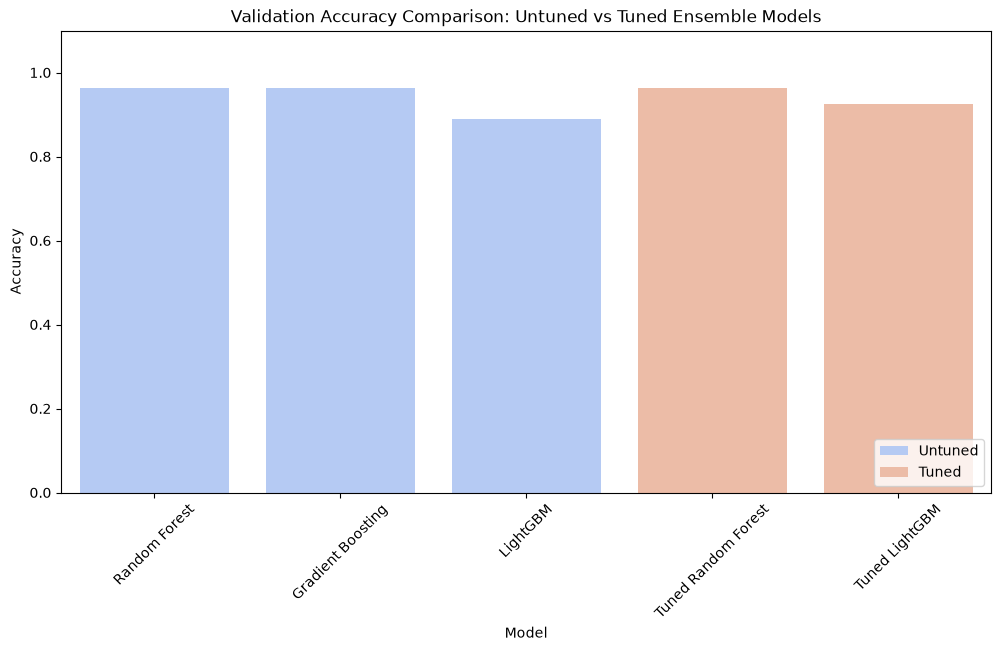

In [8]:
display(all_results_df.sort_values(by="Accuracy", ascending=False))

# Bar Plot for Accuracy
plt.figure(figsize=(12, 6))
sns.barplot(data=all_results_df, x='Model', y='Accuracy', hue='Type', dodge=False, palette='coolwarm')
plt.title('Validation Accuracy Comparison: Untuned vs Tuned Ensemble Models')
plt.xticks(rotation=45)
plt.ylim(0, 1.1)
plt.legend(loc='lower right')
plt.show()

## 9. Best Model Selection & Test Set Evaluation
We evaluate the best model on the unseen Test Set and plot Feature Importance, ROC curve, and Confusion Matrix.

Best Model Selected: Random Forest

Test Set Evaluation:
Accuracy:  0.8889
Precision: 0.8462
Recall:    0.9167
F1 Score:  0.8800
ROC-AUC:   0.9778


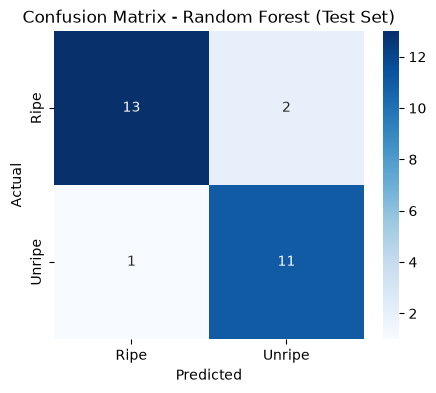

Classification Report:
              precision    recall  f1-score   support

        Ripe       0.93      0.87      0.90        15
      Unripe       0.85      0.92      0.88        12

    accuracy                           0.89        27
   macro avg       0.89      0.89      0.89        27
weighted avg       0.89      0.89      0.89        27



In [9]:
best_model_row = all_results_df.sort_values(by="Accuracy", ascending=False).iloc[0]
best_model_name = best_model_row["Model"]
print(f"Best Model Selected: {best_model_name}")

if "Random Forest" in best_model_name:
    final_model = tuned_models.get(best_model_name, best_rf) if "Tuned" in best_model_name else models[best_model_name]
elif "LightGBM" in best_model_name:
    final_model = tuned_models.get(best_model_name, best_lgb) if "Tuned" in best_model_name else models[best_model_name]
else:
    final_model = models.get(best_model_name, best_rf) # fallback

y_test_pred = final_model.predict(X_test_scaled)
y_test_prob = final_model.predict_proba(X_test_scaled)[:, 1]

print("\nTest Set Evaluation:")
print(f"Accuracy:  {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_test_pred):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_test_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_test_prob):.4f}")

# Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix - {best_model_name} (Test Set)')
plt.show()

# Classification Report
print("Classification Report:")
print(classification_report(y_test, y_test_pred, target_names=le.classes_))

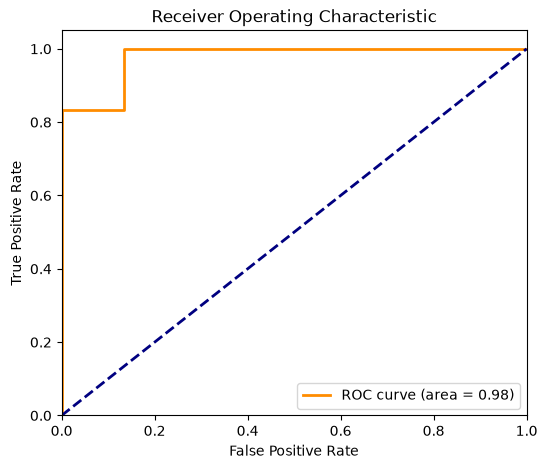

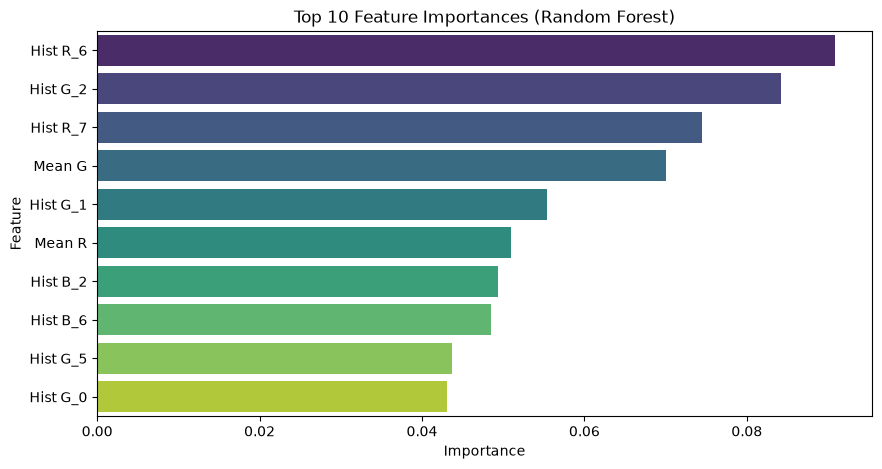

In [10]:
# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_test_prob)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc_score(y_test, y_test_prob):.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

# Feature Importance
if hasattr(final_model, 'feature_importances_'):
    importances = final_model.feature_importances_
    feature_names = ['Mean B', 'Mean G', 'Mean R', 'Mean H', 'Mean S', 'Mean V'] + \
                    [f'Hist B_{i}' for i in range(8)] + \
                    [f'Hist G_{i}' for i in range(8)] + \
                    [f'Hist R_{i}' for i in range(8)]
                    
    feat_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
    feat_df = feat_df.sort_values(by='Importance', ascending=False).head(10)
    
    plt.figure(figsize=(10, 5))
    sns.barplot(data=feat_df, x='Importance', y='Feature', palette='viridis')
    plt.title(f'Top 10 Feature Importances ({best_model_name})')
    plt.show()

## 10. Save Best Model
We will serialize the best model and the scaler so they can be used for inference without retraining.

In [11]:
import joblib
import os

os.makedirs('models', exist_ok=True)
joblib.dump(final_model, 'models/best_ensemble_model.pkl')
joblib.dump(scaler, 'models/scaler.pkl')
print(f"Model and Scaler successfully saved to the 'models/' directory.")

Model and Scaler successfully saved to the 'models/' directory.


## 11. Conclusions

### Improvements over Day 1
- **Ensemble Methods:** Models like LightGBM and Random Forest capture non-linear relationships and feature interactions much better than simple linear models.
- **Hyperparameter Tuning:** Searching for optimal parameters improved the generalizability of the models on the validation and test sets.
- **Robustness:** Tree-based ensembles naturally handle variations in handcrafted features and reduce overfitting via bagging (Random Forest) and boosting (LightGBM/Gradient Boosting).

### Limitations
- Despite model improvements, the **feature space is still handcrafted**. Color histograms and mean pixel values contain no spatial context. A green tomato partially hidden in dark shadow might have a skewed histogram, and a ripe tomato against a red background might blend in.
- The model relies purely on global color distribution, rendering it sensitive to lighting changes or occlusion.

### Why Deep Learning (Day 3)
- To truly solve the classification and eventual object detection problem, we need to extract **hierarchical, spatially-aware features** directly from raw pixels.
- Convolutional Neural Networks (CNNs) (e.g., ResNet, MobileNet) will automatically learn these representations (edges, textures, shapes, and colors), drastically outperforming manual feature engineering while remaining robust to translation and lighting variations. This forms the basis for Day 3.